# ¿Cuándo un accidente se convierte en colapso del tráfico? Patrones de accidentes de alto impacto en EE.UU. (2016–2023)

**Curso:** Big Data — Universidad Nacional de Juliaca (UNAJ) · 2026-2
**Docente:** Mg. Leibnihtz Abrahan Ayamamani Choque
**Entrega:** Proyecto Unidad 1 — EDA y calidad de datos
**Tema asignado:** Movilidad urbana y patrones de congestión
**Integrantes:** Charca Condori Yordi Brayan · Chura Puma Cristian Erik · Condori Quispe Kewin Erick · Inofuente Trujillo David Alex · Vargas Idme Vladimir Yordanov

> **Cómo leer este notebook (también si nunca estudiaste tránsito).** La sección 1.2 explica en pocos minutos los términos y las unidades de medida que usa el dataset.
> Cada tabla o gráfico va seguido de una interpretación en lenguaje simple: **dato → significado → consecuencia para la pregunta**.

| Sección | Contenido mínimo de la rúbrica | Criterio |
|---|---|---|
| 0 | Preparación reproducible: raíz del proyecto, dependencias y descarga del dataset | 2 |
| 1 | Nombre del proyecto, tema e integrantes (contenido 1) | 1 |
| 2 | Pregunta motivadora y utilidad esperada (contenido 2) | 1 |
| 3 | Fuente, periodo y condiciones de uso (contenido 3) | 2 |
| 4 | Unidad de análisis: qué representa una fila (contenido 4) | 2 |
| 5 | Carga reproducible: `head()`, `shape`, `info()` (contenido 5) | 2 · 3 |
| 6 | Perfil descriptivo con `describe()` e interpretación (contenido 6) | 3 |
| 7 | Diccionario de las columnas relevantes (contenido 7) | 3 |
| 8 | Evaluación de calidad con reglas justificadas (contenido 8) | 4 |
| 9 | Diagnóstico final: problemas, impacto y acción (contenido 9) | 4 |
| 10 | Trazabilidad: tablas y gráficos exportados | — |

> **Para reproducir todos los resultados:** abrir el notebook con el kernel del entorno del proyecto (`pip install -r requirements.txt`) y ejecutar **Kernel → Restart & Run All**. Funciona desde cualquier carpeta del repositorio.
> Si el archivo `data/bronze/us_accidents/US_Accidents_March23.csv` no existe, la celda 0.3 lo descarga de Kaggle (≈ 650 MB comprimido, ≈ 3 GB descomprimido). La carga de la muestra tarda entre 1 y 3 minutos.

---
## 0. Preparación reproducible

El notebook sigue la misma organización que el resto del repositorio `EDA` (arquitectura *medallion*):

| Capa | Carpeta | Qué contiene |
|---|---|---|
| **Bronze** | `data/bronze/us_accidents/` | El CSV original de Kaggle, **sin modificar**, y un `manifest.json` con su tamaño y huella SHA-256 |
| **Gold** | `data/gold/us_accidents/` | Diccionario de datos, perfil descriptivo y reporte de calidad (sección 10) |
| **Outputs** | `outputs/us_accidents/` | Gráficos del notebook en PNG |

> No se genera capa **Silver**: esta entrega termina en el diagnóstico de calidad y **no limpia ni elimina registros**.

**Preparar el entorno en otra computadora** (una sola vez, desde la raíz del repositorio; Python 3.11–3.13, probado con 3.12)
```bash
python -m venv BigData20262
BigData20262\Scripts\activate          # Windows  ·  Linux/macOS: source BigData20262/bin/activate
python -m pip install -r requirements.txt
```
Luego abrir este notebook y elegir como kernel el Python de `BigData20262`.

**Reglas de reproducibilidad aplicadas**
- La raíz del proyecto se localiza buscando las carpetas `data/` y `notebooks/`; todas las rutas se construyen desde ella. No hay rutas propias de una computadora (como `C:\Users\...`).
- El notebook no instala paquetes: usa el entorno del proyecto y se detiene con un mensaje claro si falta alguna librería.
- La muestra usa una semilla fija, de modo que cualquier persona obtiene los mismos registros y resultados.

**Credenciales de Kaggle** (solo se necesitan si el CSV todavía no está en Bronze)
1. En Kaggle abrir **Settings → API** y generar un token.
2. Guardarlo en la carpeta `.kaggle` del usuario (`C:\Users\TU_USUARIO\.kaggle\` en Windows, `~/.kaggle/` en Linux/macOS):
   - token nuevo (**API Tokens → Generate**): guardar el texto en un archivo llamado `access_token`;
   - clave antigua (**Create Legacy API Key**): guardar el `kaggle.json` descargado.
3. No copiar el token al repositorio ni mostrarlo en pantalla.

*Alternativa sin token:* descargar manualmente el ZIP desde Kaggle, descomprimirlo y colocar `US_Accidents_March23.csv` en `data/bronze/us_accidents/`.

In [15]:
# Celda 0.1: localizar la raíz del proyecto y definir las capas de datos
import hashlib
import importlib.util
import json
import os
import platform
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Localiza la raíz del repositorio por sus carpetas data/ y notebooks/."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto EDA (carpetas data/ y notebooks/).")


PROJECT_ROOT = find_project_root(Path.cwd())
BRONZE_DIR = PROJECT_ROOT / "data" / "bronze" / "us_accidents"
GOLD_DIR = PROJECT_ROOT / "data" / "gold" / "us_accidents"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "us_accidents"

for folder in (BRONZE_DIR, GOLD_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Proyecto : {PROJECT_ROOT}")
print(f"Python   : {sys.version.split()[0]} ({platform.system()})")
print(f"Bronze   : {BRONZE_DIR.relative_to(PROJECT_ROOT)}")
print(f"Gold     : {GOLD_DIR.relative_to(PROJECT_ROOT)}")
print(f"Outputs  : {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Proyecto : C:\Users\Erik\Documents\EDA-TF\EDA_2026_2
Python   : 3.12.10 (Windows)
Bronze   : data\bronze\us_accidents
Gold     : data\gold\us_accidents
Outputs  : outputs\us_accidents


In [16]:
# Celda 0.2: verificar dependencias sin modificar el entorno y registrar versiones
REQUERIDAS = ["pandas", "numpy", "matplotlib"]   # kaggle solo se exige si hay que descargar (0.3)
faltantes = [lib for lib in REQUERIDAS if importlib.util.find_spec(lib) is None]
if faltantes:
    raise ModuleNotFoundError(
        "Faltan dependencias: " + ", ".join(faltantes) +
        ". Ejecute desde la raíz del proyecto: python -m pip install -r requirements.txt"
    )

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def guardar_figura(fig, nombre: str) -> None:
    """Guarda cada gráfico en outputs/us_accidents/ para el informe."""
    fig.savefig(OUTPUT_DIR / f"{nombre}.png", dpi=120, bbox_inches="tight")


print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("matplotlib:", matplotlib.__version__)

pandas    : 3.0.6
numpy     : 2.5.4
matplotlib: 3.11.2


### 0.3 Obtención del dataset (capa Bronze)
La celda es **idempotente**: si el CSV ya está en Bronze no lo vuelve a descargar (salvo `FORCE_DOWNLOAD = True`). Luego registra en `manifest.json` el tamaño y la huella SHA-256 del archivo, para comprobar que todos trabajan con **el mismo archivo original**.

In [17]:
# Celda 0.3: descargar el CSV original en Bronze (solo si falta) y registrar su huella
DATASET_SLUG = "sobhanmoosavi/us-accidents"
ARCHIVO = "US_Accidents_March23.csv"
TAMANO_ESPERADO = 3_058_183_727          # bytes, según Kaggle (versión de marzo 2023)
RUTA = BRONZE_DIR / ARCHIVO
FORCE_DOWNLOAD = False

if FORCE_DOWNLOAD or not RUTA.is_file():
    kaggle_dir = Path(os.environ.get("KAGGLE_CONFIG_DIR", Path.home() / ".kaggle"))
    token_en_entorno = "KAGGLE_API_TOKEN" in os.environ or {"KAGGLE_USERNAME", "KAGGLE_KEY"} <= os.environ.keys()
    token_en_archivo = (kaggle_dir / "access_token").is_file() or (kaggle_dir / "kaggle.json").is_file()
    if not (token_en_entorno or token_en_archivo):
        raise FileNotFoundError(
            f"No se encontró {ARCHIVO} en {BRONZE_DIR.relative_to(PROJECT_ROOT)} ni un token de Kaggle en {kaggle_dir}. "
            "Configure el token (ver sección 0) o coloque el CSV manualmente en esa carpeta."
        )
    if importlib.util.find_spec("kaggle") is None:
        raise ModuleNotFoundError("Para descargar el dataset falta la librería kaggle: python -m pip install -r requirements.txt")
    print("Descargando desde Kaggle (≈ 650 MB, puede tardar varios minutos)...")
    subprocess.run([sys.executable, "-m", "kaggle", "datasets", "download",
                    "-d", DATASET_SLUG, "--unzip", "-p", str(BRONZE_DIR)], check=True)

if not RUTA.is_file():
    raise FileNotFoundError(f"La descarga no produjo el archivo esperado: {RUTA}")
if RUTA.stat().st_size != TAMANO_ESPERADO:
    print(f"⚠️ El tamaño ({RUTA.stat().st_size:,} bytes) no coincide con la versión de Kaggle "
          f"({TAMANO_ESPERADO:,} bytes): los resultados pueden diferir.")


def sha256(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


archivos = [{"name": RUTA.name, "bytes": RUTA.stat().st_size, "sha256": sha256(RUTA)}]
ruta_manifest = BRONZE_DIR / "manifest.json"
manifest = json.loads(ruta_manifest.read_text(encoding="utf-8")) if ruta_manifest.is_file() else {}
# Solo se reescribe si el archivo cambió: así la fecha de ingesta no se modifica en cada ejecución
if manifest.get("files") != archivos:
    manifest = {
        "dataset": DATASET_SLUG,
        "source_url": f"https://www.kaggle.com/datasets/{DATASET_SLUG}",
        "license": "CC BY-NC-SA 4.0",
        "ingested_at_utc": datetime.now(timezone.utc).isoformat(),
        "layer": "bronze",
        "files": archivos,
    }
    ruta_manifest.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

print("Bronze listo (dato original, sin transformación):")
for entry in manifest["files"]:
    print(f"  {entry['name']}  {entry['bytes'] / 1024**3:.2f} GB  SHA-256 {entry['sha256'][:12]}…")

Bronze listo (dato original, sin transformación):
  US_Accidents_March23.csv  2.85 GB  SHA-256 e3e9f962e3e2…


---
## 1. Proyecto, tema e integrantes

### 1.1 Ficha del proyecto
- **Nombre del proyecto:** ¿Cuándo un accidente se convierte en colapso del tráfico?
- **Tema:** movilidad urbana y patrones de congestión, estudiados a través de los **accidentes de tránsito que más alteran el tráfico**. Con una muestra de **540 988 accidentes** (2016–2023, 49 estados de EE.UU.) describimos cuándo, dónde y bajo qué condiciones se concentran, y evaluamos si los datos son confiables para orientar decisiones de control vial.
- **¿Por qué es un caso de Big Data?** Por su **volumen** (~7,7 millones de registros y ~3 GB), su **variedad** (tiempo, ubicación, clima e infraestructura en una misma tabla) y porque combina **varias fuentes** de datos de tráfico que no registran la información de la misma forma.
- **Integrantes:**
    - Charca Condori Yordi Brayan
    - Chura Puma Cristian Erik
    - Condori Quispe Kewin Erick
    - Inofuente Trujillo David Alex
    - Vargas Idme Vladimir Yordanov

### 1.2 Accidentes y tráfico en 5 minutos (glosario)

| Término | Qué significa en este trabajo |
|---|---|
| **Severidad** (`Severity`) | Escala de 1 a 4 que mide **cuánto afecta el accidente al tráfico** (por ejemplo, cuánto retraso genera). **No** mide la gravedad de las lesiones. 1 = impacto bajo, 4 = impacto alto. |
| **Accidente de alto impacto** | En este trabajo, un accidente de **severidad 3 o 4**: es el que convierte un incidente en **colapso del tráfico**. |
| **Fuente** (`Source`) | Proveedor de datos de tráfico que reportó el accidente. Hay tres: Source1, Source2 y Source3. Cada una recoge la información a partir de departamentos de transporte, policía, cámaras y sensores. |
| **Tramo afectado** (`Distance(mi)`) | Longitud de vía afectada por el accidente. |
| **Hora local** | `Start_Time` está en la hora de la zona donde ocurrió el accidente (`Timezone`). EE.UU. tiene 4 zonas horarias continentales. |
| **Elementos de la vía** | Variables Verdadero/Falso que indican si cerca del accidente hay semáforo, cruce peatonal, intersección, señal de pare o rotonda. |

**Unidades de medida (sistema estadounidense) y su equivalencia:**

| Unidad | Equivalencia | Columna |
|---|---|---|
| milla (mi) | 1 mi ≈ 1,61 km | `Distance(mi)`, `Visibility(mi)` |
| grado Fahrenheit (°F) | °C = (°F − 32) × 5/9; 32 °F = 0 °C | `Temperature(F)` |
| pulgada (in) | 1 in = 2,54 cm | `Precipitation(in)` |
| pulgada de mercurio (inHg) | presión normal ≈ 29,9 inHg (1013 hPa) | `Pressure(in)` |
| millas por hora (mph) | 1 mph ≈ 1,61 km/h | `Wind_Speed(mph)` |

---
## 2. Pregunta motivadora y utilidad esperada

> ### ¿Cuándo, dónde y bajo qué condiciones un accidente deja de ser un incidente aislado y se convierte en un colapso del tráfico?

Cada accidente bloquea vías, retrasa ambulancias y genera congestión que afecta a miles de personas que no estuvieron involucradas. Sin embargo, los recursos de control vial suelen distribuirse de forma uniforme, sin considerar **cuándo y dónde** el riesgo es realmente mayor.

| | |
|---|---|
| **¿Qué queremos describir?** | Los patrones de hora, día, clima y tipo de vía en que se concentran los accidentes de mayor impacto en el tráfico (severidad 3–4). |
| **¿Qué decisión mejora?** | La asignación de patrullaje, semaforización y servicios de emergencia por franja horaria y zona. |
| **¿Quién se beneficia?** | Departamentos de transporte (usuario principal), policía de tránsito y servicios de emergencia. |
| **Tipo de propósito** | Mejorar una decisión. |

**Sub-preguntas que guiarán el análisis** (todas descriptivas, sin afirmar causalidad):

| # | Sub-pregunta | Variables | Dimensión |
|---|---|---|---|
| 1 | ¿En qué horas y días se concentran los accidentes de alto impacto? | `Start_Time`, `Severity` | Tiempo |
| 2 | ¿En qué estados y ciudades se concentran? | `State`, `City`, `Start_Lat`, `Start_Lng` | Lugar |
| 3 | ¿Bajo qué condiciones climáticas aumenta la proporción de alto impacto? | `Weather_Condition`, `Visibility(mi)`, `Precipitation(in)` | Clima |
| 4 | ¿Qué elementos de la vía acompañan a los accidentes de alto impacto? | `Traffic_Signal`, `Crossing`, `Junction`, `Stop`, `Roundabout` | Infraestructura |


---
## 3. Fuente, período y condiciones de uso

### 3.1 Ficha de la fuente

| Campo | Valor |
|---|---|
| Dataset | *US Accidents (2016–2023)* — Kaggle: `kaggle.com/datasets/sobhanmoosavi/us-accidents` |
| Autor / mantenedor | Sobhan Moosavi |
| Origen de los datos | APIs de tráfico que transmiten incidentes reportados por departamentos de transporte, policía, cámaras y sensores viales |
| Período | Febrero 2016 – Marzo 2023 |
| Cobertura | 49 estados de EE.UU. continental |
| Tamaño original | ~7,7 millones de registros, 46 columnas (~3 GB en CSV) |
| Archivos del dataset | Un único archivo: `US_Accidents_March23.csv` (3 058 183 727 bytes) |
| Ubicación en el proyecto | `data/bronze/us_accidents/US_Accidents_March23.csv` (descargado por la celda 0.3) |
| Fecha de la versión | 28-may-2023 (última actualización publicada en Kaggle) |
| Licencia / condiciones de uso | CC BY-NC-SA 4.0: uso no comercial, citando a los autores |
| Citas solicitadas por el autor | Moosavi et al. (2019a). *A Countrywide Traffic Accident Dataset*. arXiv:1906.05409 · Moosavi et al. (2019b). *Accident Risk Prediction based on Heterogeneous Sparse Data*. ACM SIGSPATIAL |

### 3.2 Alcance: qué se carga y por qué

| Decisión | Justificación |
|---|---|
| **Se cargan 29 de las 46 columnas** | Se eligieron las columnas de tiempo, lugar, severidad, clima y vía (las que usa la pregunta) y las necesarias para evaluar calidad (`ID`, `Source`, `End_Time`, `End_Lat`, `Weather_Timestamp`). |
| **Columnas excluidas** | Texto libre (`Description`, `Street`), columnas redundantes con otras (`County`, `Airport_Code`, `Wind_Chill(F)`, `Wind_Direction`, `Civil_Twilight`, `Nautical_Twilight`, `Astronomical_Twilight`) y elementos de la vía muy poco frecuentes (`Amenity`, `Bump`, `Give_Way`, `No_Exit`, `Railway`, `Station`, `Traffic_Calming`, `Turning_Loop`). |
| **Muestra aleatoria del 7 %** (~541 000 filas) | El archivo completo ocupa varios GB en memoria y no es manejable en una computadora personal. Un 7 % aleatorio conserva la distribución del total y sigue siendo una muestra muy grande. |
| **Lectura por bloques de 500 000 filas** | Evita cargar los 3 GB de una sola vez: se toma el 7 % de cada bloque y luego se unen. |
| **Semilla fija** (`random_state=42`) | Garantiza que cualquier persona que ejecute el notebook obtenga **exactamente la misma muestra** y los mismos resultados. |

---
## 4. Unidad de análisis

**Cada fila representa un accidente de tránsito reportado.** Contiene:
- **cuándo** ocurrió (`Start_Time`, `End_Time`),
- **dónde** (coordenadas, ciudad, estado),
- **el clima** en ese momento (temperatura, visibilidad, lluvia, viento),
- **los elementos de la vía** cercanos (semáforo, cruce, pare, etc.),
- y su **severidad (1 a 4)**, que mide el impacto del accidente en el tráfico.

| Elemento | Valor |
|---|---|
| Unidad de análisis | El accidente reportado |
| Clave (identificador único) | `ID` (verificado como único en la sección 8.2) |
| Variable objetivo de la pregunta | `Severity` (alto impacto = 3 o 4) |
| Variable de control | `Source` (cada fuente registra los datos de forma distinta, ver 8.4) |


---
## 5. Carga reproducible y evidencia básica

In [18]:
# Celda 5.1: carga reproducible por bloques con una muestra aleatoria fija
COLUMNAS = ["ID","Source","Severity","Start_Time","End_Time",
            "Start_Lat","Start_Lng","End_Lat","End_Lng","Distance(mi)",
            "City","State","Zipcode","Country","Timezone",
            "Weather_Timestamp","Temperature(F)","Humidity(%)","Pressure(in)",
            "Visibility(mi)","Wind_Speed(mph)","Precipitation(in)","Weather_Condition",
            "Traffic_Signal","Crossing","Junction","Stop","Roundabout","Sunrise_Sunset"]
FRACCION, SEMILLA = 0.07, 42
TAMANO_BLOQUE = 500_000

t0 = time.perf_counter()
partes, filas_originales = [], 0
# Zipcode se lee como texto: mezcla códigos de 5 dígitos con códigos extendidos ("12345-6789")
for bloque in pd.read_csv(RUTA, usecols=COLUMNAS, dtype={"Zipcode": str}, chunksize=TAMANO_BLOQUE):
    filas_originales += len(bloque)
    partes.append(bloque.sample(frac=FRACCION, random_state=SEMILLA))
df = pd.concat(partes, ignore_index=True)

print(f"Carga completada en {time.perf_counter() - t0:.0f} s")
print(f"Filas del archivo original : {filas_originales:,}")
print(f"Filas de la muestra ({FRACCION:.0%})  : {len(df):,}")

Carga completada en 35 s
Filas del archivo original : 7,728,394
Filas de la muestra (7%)  : 540,988


In [19]:
# Celda 5.2: primeras filas
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),City,State,Zipcode,Country,Timezone,Weather_Timestamp,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Crossing,Junction,Roundabout,Stop,Traffic_Signal,Sunrise_Sunset
0,A-104248,Source2,2,2016-04-25 17:18:11,2016-04-25 18:18:11,33.939304,-117.218231,NaN,NaN,0.01,Moreno Valley,CA,92553,US,US/Pacific,2016-04-25 16:58:00,63.9,29.0,29.80,10.0,11.5,NaN,Clear,False,False,False,False,False,Day
1,A-199683,Source2,2,2017-01-10 09:40:16,2017-01-10 10:10:02,42.549671,-71.847313,NaN,NaN,0.01,Fitchburg,MA,01420,US,US/Eastern,2017-01-10 09:52:00,19.0,71.0,30.66,10.0,3.5,NaN,Clear,False,False,False,False,False,Day
2,A-140206,Source2,3,2016-09-02 17:27:56,2016-09-02 18:27:56,26.203491,-80.143852,NaN,NaN,0.00,Fort Lauderdale,FL,33334,US,US/Eastern,2016-09-02 17:53:00,91.0,48.0,29.99,10.0,12.7,NaN,Clear,False,False,False,False,False,Day
3,A-132821,Source2,2,2016-09-29 18:07:37,2016-09-29 18:51:28,27.440348,-82.575432,NaN,NaN,0.00,Bradenton,FL,34207-3610,US,US/Eastern,2016-09-29 18:05:00,77.0,88.0,30.02,1.5,3.5,0.08,Heavy Thunderstorms and Rain,False,False,False,False,True,Day
4,A-408710,Source2,3,2017-05-03 12:12:18,2017-05-03 12:44:00,33.901752,-118.370316,NaN,NaN,0.01,Hawthorne,CA,90250,US,US/Pacific,2017-05-03 11:53:00,72.0,61.0,29.96,10.0,8.1,NaN,Clear,False,False,False,False,False,Day


In [20]:
# Celda 5.3: dimensiones de la muestra (filas, columnas)
df.shape

(540988, 29)

In [21]:
# Celda 5.4: tipos de dato, nulos y memoria
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 540988 entries, 0 to 540987
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ID                 540988 non-null  str    
 1   Source             540988 non-null  str    
 2   Severity           540988 non-null  int64  
 3   Start_Time         540988 non-null  str    
 4   End_Time           540988 non-null  str    
 5   Start_Lat          540988 non-null  float64
 6   Start_Lng          540988 non-null  float64
 7   End_Lat            302822 non-null  float64
 8   End_Lng            302822 non-null  float64
 9   Distance(mi)       540988 non-null  float64
 10  City               540969 non-null  str    
 11  State              540988 non-null  str    
 12  Zipcode            540862 non-null  str    
 13  Country            540988 non-null  str    
 14  Timezone           540446 non-null  str    
 15  Weather_Timestamp  532555 non-null  str    
 16  Temperature(F

**Interpretación de la carga**

- La muestra contiene **540 988 accidentes y 29 columnas**, y ocupa ~414 MB en memoria (medido con `memory_usage="deep"`) frente a ~3 GB en disco.
- **Tipos que llegaron mal:** `Start_Time`, `End_Time` y `Weather_Timestamp` llegan como **texto**, no como fecha; se convierten en la sección 6.1. `Severity` es entera, las coordenadas y variables climáticas son decimales, y las variables de la vía son booleanas (Verdadero/Falso).
- **Columnas completas (0 nulos):** `ID`, `Source`, `Severity`, `Start_Time`, `End_Time`, `Start_Lat`, `Start_Lng`, `Distance(mi)`, `State` y los elementos de la vía. Es decir, **las variables centrales de la pregunta (cuándo, dónde, qué severidad y qué tipo de vía) están completas**.
- **Columnas con nulos** (se cuantifican en la sección 8.1):

| Columna | Nulos | % |
|---|---|---|
| `End_Lat` / `End_Lng` | 238 166 | 44,02 % |
| `Precipitation(in)` | 154 617 | 28,58 % |
| `Wind_Speed(mph)` | 39 968 | 7,39 % |
| `Visibility(mi)` | 12 456 | 2,30 % |
| `Weather_Condition` | 12 232 | 2,26 % |
| `Temperature(F)` | 11 505 | 2,13 % |
| `Weather_Timestamp` | 8 433 | 1,56 % |

- **Consecuencia:** se puede describir el **cuándo y el dónde** sin pérdidas, pero el análisis por **clima** tendrá faltantes que hay que controlar.

---
## 6. Perfil descriptivo

### 6.1 Variables derivadas: de texto a información útil
Se convierten las fechas y se crean variables que la pregunta necesita (hora, día, año, duración y alto impacto). No se elimina ningún registro: las fechas que no se puedan leer quedan como nulas y se miden en la sección 8.

In [22]:
for col in ["Start_Time", "End_Time", "Weather_Timestamp"]:
    df[col] = pd.to_datetime(df[col], format="mixed", errors="coerce")

df["Anio"] = df["Start_Time"].dt.year
df["Hora"] = df["Start_Time"].dt.hour
df["Dia"] = df["Start_Time"].dt.day_name()
df["Duracion_min"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60
df["Alto_impacto"] = df["Severity"] >= 3

df[["Start_Time", "End_Time", "Anio", "Hora", "Dia", "Duracion_min", "Severity", "Alto_impacto"]].head()

,Start_Time,End_Time,Anio,Hora,Dia,Duracion_min,Severity,Alto_impacto
0,2016-04-25 17:18:11,2016-04-25 18:18:11,2016,17,Monday,60.000000,2,False
1,2017-01-10 09:40:16,2017-01-10 10:10:02,2017,9,Tuesday,29.766667,2,False
2,2016-09-02 17:27:56,2016-09-02 18:27:56,2016,17,Friday,60.000000,3,True
3,2016-09-29 18:07:37,2016-09-29 18:51:28,2016,18,Thursday,43.850000,2,False
4,2017-05-03 12:12:18,2017-05-03 12:44:00,2017,12,Wednesday,31.700000,3,True


### 6.2 Variables numéricas: `describe()` explicado
Además de los cuartiles, se agregan los **percentiles 1 % y 99 %**: si el máximo o el mínimo están muy lejos de ellos, hay valores extremos que revisar.

In [23]:
cols_num = ["Severity", "Start_Lat", "Start_Lng", "End_Lat", "End_Lng", "Distance(mi)",
            "Duracion_min", "Temperature(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
perfil_num = df[cols_num].describe(percentiles=[.01, .25, .5, .75, .99]).T
perfil_num["asimetria"] = df[cols_num].skew()
perfil_num.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,asimetria
Severity,540988.0,2.21,0.49,1.00,2.00,2.00,2.00,2.00,4.00,4.00,1.82
Start_Lat,540988.0,36.21,5.07,24.56,25.73,33.41,35.83,40.09,47.47,49.00,-0.07
Start_Lng,540988.0,-94.71,17.39,-124.55,-122.97,-117.22,-87.76,-80.36,-71.49,-67.55,-0.48
End_Lat,302822.0,36.27,5.27,24.57,25.69,33.46,36.20,40.19,47.28,49.00,-0.16
End_Lng,302822.0,-95.74,18.11,-124.55,-123.20,-117.76,-88.03,-80.25,-72.88,-67.71,-0.36
Distance(mi),540988.0,0.56,1.81,0.00,0.00,0.00,0.03,0.46,7.00,333.63,26.51
Duracion_min,540988.0,451.81,13591.41,3.00,15.00,31.35,74.82,125.07,796.54,1578299.10,46.22
Temperature(F),529483.0,61.66,19.01,-89.00,12.00,49.00,64.00,76.00,96.00,172.00,-0.51
Humidity(%),528755.0,64.85,22.81,1.00,12.00,48.00,67.00,84.00,100.00,100.00,-0.40
Pressure(in),531162.0,29.54,1.00,0.30,24.60,29.37,29.86,30.03,30.44,39.45,-3.72


**Interpretación de las variables numéricas** (dato → significado → consecuencia)

- **Severity:** media 2,21 y mediana 2 → la mayoría de accidentes son de impacto moderado → los de alto impacto (3–4) son el grupo minoritario que interesa.
- **Start_Lat / Start_Lng:** latitudes entre 24,56 y 49,00 y longitudes entre −124,55 y −67,55 → todas caen dentro de EE.UU. continental → la ubicación es **válida**.
- **Distance(mi):** mediana de solo 0,03 millas y al menos el 25 % con distancia **0**, pero el máximo llega a **333,63 millas** → distribución muy sesgada → se revisa como posible valor por defecto (8.5).
- **Temperature(F):** mínimo **−89 °F** (−67 °C) y máximo **172 °F** (78 °C) → valores físicamente imposibles en EE.UU. → errores del sensor (8.3).
- **Pressure(in):** mínimo **0,30 inHg** y máximo **39,45 inHg**, cuando la presión normal ronda 29,9 → errores de registro (8.3). El percentil 1 % es **24,6** porque se trata de **presión de estación** (sin corregir al nivel del mar): en ciudades altas como Denver (~1 600 m) la presión es naturalmente menor, así que **no** es un error.
- **Wind_Speed(mph):** máximo de **243 mph** (391 km/h), más que un huracán extremo → valor atípico (8.3).
- **Visibility(mi):** los percentiles 25, 50 y 75 valen exactamente **10** → 10 millas parece ser el **valor máximo que reporta el sensor**, no una medición exacta → la visibilidad solo distingue bien los casos de visibilidad **reducida**.
- **Humidity(%):** entre 1 y 100 → rango válido.
- **Precipitation(in):** solo 386 371 valores (28,58 % nulos) y la mayoría son 0 → es la variable climática **menos confiable**.

### 6.3 Variables categóricas: ¿cuántas categorías hay y cuál domina?

In [24]:
cols_cat = ["ID", "Source", "City", "State", "Zipcode", "Country", "Timezone",
            "Weather_Condition", "Sunrise_Sunset"]
perfil_cat = pd.DataFrame({
    "no_nulos": df[cols_cat].notna().sum(),
    "categorias": df[cols_cat].nunique(),
    "mas_frecuente": [df[c].value_counts().index[0] for c in cols_cat],
    "frecuencia": [df[c].value_counts().iloc[0] for c in cols_cat],
})
perfil_cat["% del total"] = (perfil_cat["frecuencia"] / len(df) * 100).round(2)
perfil_cat

,no_nulos,categorias,mas_frecuente,frecuencia,% del total
ID,540988,540988,A-104248,1,0.00
Source,540988,3,Source1,302822,55.98
City,540969,9667,Miami,12915,2.39
State,540988,49,CA,121832,22.52
Zipcode,540862,136468,91761,787,0.15
Country,540988,1,US,540988,100.00
Timezone,540446,4,US/Eastern,250575,46.32
Weather_Condition,528756,108,Fair,179038,33.09
Sunrise_Sunset,539299,2,Day,373789,69.09


In [25]:
cols_via = ["Traffic_Signal", "Crossing", "Junction", "Stop", "Roundabout"]
(df[cols_via].mean() * 100).round(2).sort_values(ascending=False).to_frame("% de accidentes con el elemento")

,% de accidentes con el elemento
Traffic_Signal,14.77
Crossing,11.39
Junction,7.38
Stop,2.78
Roundabout,0.00


**Interpretación de las variables categóricas**

- **ID:** 540 988 valores distintos en 540 988 filas → cada accidente tiene un identificador propio.
- **Source:** 3 fuentes; `Source1` aporta 302 822 registros (56 %) → que haya fuentes distintas puede generar diferencias en cómo se registra cada accidente → se evalúa en 8.4.
- **State:** 49 estados; **California concentra 121 832 accidentes (22,5 %)** → fuerte concentración geográfica.
- **City:** 9 667 ciudades; Miami es la más frecuente (12 915).
- **Country:** un solo valor (US) → no aporta información.
- **Timezone:** 4 zonas horarias; la más frecuente es US/Eastern (250 575) → las horas están en **hora local**, lo que permite comparar "las 8 a. m." entre estados.
- **Weather_Condition:** **108 categorías**, con "Fair" (despejado) como la más frecuente (179 038) → muchas categorías son variantes de lo mismo ("Rain", "Light Rain", "Heavy Rain") y deberán agruparse para el análisis.
- **Sunrise_Sunset:** el 69,3 % de los accidentes con dato ocurre de día (373 789 de 539 299).
- **Elementos de la vía:** muestran qué porcentaje de accidentes ocurre cerca de cada elemento; las rotondas son muy poco frecuentes, por lo que cualquier conclusión sobre ellas tendrá poca muestra.

### 6.4 Distribución de la severidad (variable central)

Severity
1     0.87
2    79.68
3    16.79
4     2.65


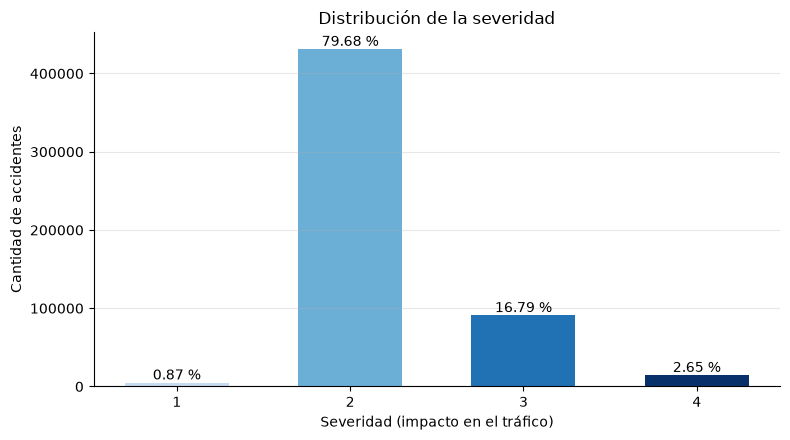

In [26]:
sev = df["Severity"].value_counts().sort_index()
sev_pct = sev / sev.sum() * 100
print(sev_pct.round(2).rename("%").to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
colores_sev = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]   # un solo tono: claro = bajo impacto, oscuro = alto
ax.bar(sev.index.astype(str), sev.values, color=colores_sev, width=0.6)
for i, (v, p) in enumerate(zip(sev.values, sev_pct.values)):
    ax.text(i, v, f"{p:.2f} %", ha="center", va="bottom")
ax.set_xlabel("Severidad (impacto en el tráfico)")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Distribución de la severidad")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "01_distribucion_severidad")
plt.show()

**Interpretación:** el **79,68 %** de los accidentes es de severidad 2. Los de **alto impacto (3–4) suman 19,44 %** (16,79 % + 2,65 %), unos 105 000 casos en la muestra: una minoría, pero suficientemente grande para describir sus patrones con confianza. La severidad 1 es casi inexistente (0,87 %).

### 6.5 ¿Dónde? Concentración por estado

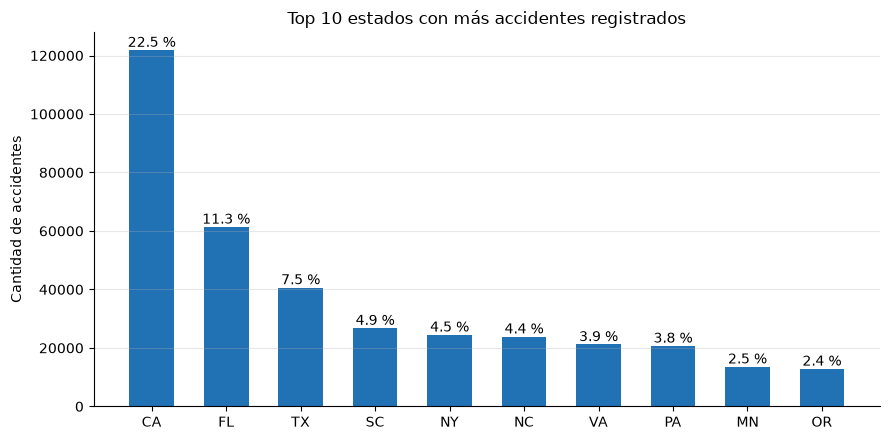

In [27]:
top_estados = df["State"].value_counts().head(10)
pct_est = top_estados / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(top_estados.index, top_estados.values, color="#2171b5", width=0.6)
for i, (v, p) in enumerate(zip(top_estados.values, pct_est.values)):
    ax.text(i, v, f"{p:.1f} %", ha="center", va="bottom")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Top 10 estados con más accidentes registrados")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "02_top10_estados")
plt.show()

**Interpretación:** California concentra el **22,5 %** de los accidentes, el doble que Florida (11,3 %), seguida de Texas (7,5 %), Carolina del Sur (4,9 %) y Nueva York (4,5 %). Solo 3 estados reúnen el **41 %** de los registros. Esta concentración puede reflejar el tamaño de la población y de la red vial, pero también una **mayor cobertura de reportes** en ciertos estados → al comparar regiones hay que tener en cuenta cuánto reporta cada fuente en cada estado.

### 6.6 ¿Cuándo? Registros por año

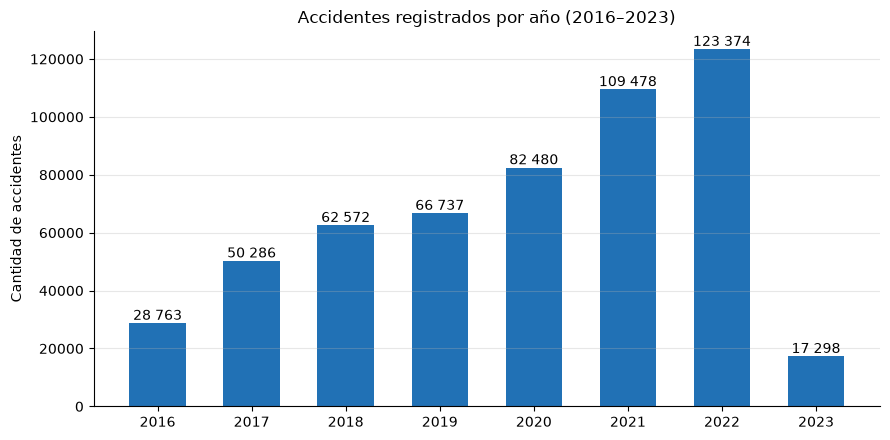

In [28]:
por_anio = df["Anio"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(por_anio.index.astype(int).astype(str), por_anio.values, color="#2171b5", width=0.6)
for i, v in enumerate(por_anio.values):
    ax.text(i, v, f"{v:,}".replace(",", " "), ha="center", va="bottom")
ax.set_ylabel("Cantidad de accidentes")
ax.set_title("Accidentes registrados por año (2016–2023)")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "03_accidentes_por_anio")
plt.show()

**Interpretación:** los accidentes registrados crecen cada año, de 50 286 en 2017 a **123 374 en 2022** (más del doble). El año **2023 aparece bajo (17 298) porque solo incluye enero a marzo**, y 2016 empieza en febrero, por lo que esos dos años **no son comparables** con los demás (se mide en 8.6). El crecimiento puede deberse en parte a una **mayor cobertura de las fuentes** con el tiempo y no necesariamente a más accidentes reales → no debe leerse como "el tránsito empeoró".

---
## 7. Diccionario de datos

### 7.1 Catálogo técnico (automático)
Generado con código para que coincida siempre con los datos reales: tipo, nulos, valores distintos y un ejemplo tomado del propio dataset.

In [29]:
catalogo = pd.DataFrame({
    "tipo_pandas": df[COLUMNAS].dtypes.astype(str),
    "no_nulos": df[COLUMNAS].notna().sum(),
    "% nulos": (df[COLUMNAS].isna().mean() * 100).round(2),
    "valores_distintos": df[COLUMNAS].nunique(),
    "ejemplo_real": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in COLUMNAS],
})
catalogo

,tipo_pandas,no_nulos,% nulos,valores_distintos,ejemplo_real
ID,str,540988,0.00,540988,A-104248
Source,str,540988,0.00,3,Source2
Severity,int64,540988,0.00,4,2
Start_Time,datetime64[ns],540988,0.00,520400,2016-04-25 17:18:11
End_Time,datetime64[ns],540988,0.00,531206,2016-04-25 18:18:11
Start_Lat,float64,540988,0.00,394427,33.939304
Start_Lng,float64,540988,0.00,395681,-117.218231
End_Lat,float64,302822,44.02,235733,34.14825
End_Lng,float64,302822,44.02,236917,-118.08481
Distance(mi),float64,540988,0.00,10915,0.01


### 7.2 Diccionario para cualquier persona

In [30]:
diccionario = pd.DataFrame([
    ("ID", "Código del accidente", "Identificador único de cada accidente", "Identificador (texto)", "Único por registro", "Verificar duplicados (unicidad)"),
    ("Source", "Fuente", "Proveedor de datos que reportó el accidente", "Categórica nominal", "Source1, Source2, Source3", "Clave: cada fuente mide distinto la severidad (8.4)"),
    ("Severity", "Severidad", "Impacto del accidente en el tráfico (no en las personas)", "Categórica ordinal", "1 (bajo) a 4 (alto)", "Define el 'colapso del tráfico' (3–4)"),
    ("Start_Time", "Inicio", "Momento en que empezó el accidente (hora local)", "Temporal", "Fecha y hora entre feb-2016 y mar-2023", "Sub-pregunta 1: hora y día"),
    ("End_Time", "Fin", "Momento en que terminó el impacto en el tráfico", "Temporal", "Posterior a Start_Time", "Mide la duración del bloqueo"),
    ("Start_Lat / Start_Lng", "Ubicación", "Coordenadas donde ocurrió el accidente", "Numérica continua", "Grados; lat. 24–50, long. −125 a −66", "Sub-pregunta 2: dónde"),
    ("End_Lat / End_Lng", "Fin del tramo", "Coordenadas donde termina el tramo afectado", "Numérica continua", "Grados; mismo rango", "Extensión del impacto (solo Source1)"),
    ("Distance(mi)", "Tramo afectado", "Longitud de vía afectada", "Numérica continua", "Millas (1 mi ≈ 1,61 km), ≥ 0", "Extensión del impacto"),
    ("City", "Ciudad", "Ciudad del accidente", "Categórica nominal", "Nombres de ciudades", "Comparar zonas"),
    ("State", "Estado", "Estado de EE.UU.", "Categórica nominal", "Código de 2 letras (49 estados)", "Comparar regiones"),
    ("Zipcode", "Código postal", "Código postal del lugar", "Categórica", "5 dígitos (a veces con extensión)", "Ubicación detallada"),
    ("Country", "País", "País del accidente", "Categórica", "Solo 'US'", "Sin aporte (valor constante)"),
    ("Timezone", "Zona horaria", "Zona horaria del lugar", "Categórica nominal", "4 zonas (US/Eastern, US/Pacific, …)", "Interpretar la hora local"),
    ("Weather_Timestamp", "Hora del clima", "Momento en que se midió el clima", "Temporal", "Cercano a Start_Time", "Comprobar que el clima corresponde al accidente"),
    ("Temperature(F)", "Temperatura", "Temperatura del aire", "Numérica continua", "°F; rango realista −40 a 130", "Contexto climático"),
    ("Humidity(%)", "Humedad", "Humedad relativa del aire", "Numérica continua", "%, 0 a 100", "Contexto climático"),
    ("Pressure(in)", "Presión", "Presión atmosférica", "Numérica continua", "inHg (presión de estación); rango realista 17 a 32", "Contexto climático"),
    ("Visibility(mi)", "Visibilidad", "Distancia a la que se ve con claridad", "Numérica continua", "Millas, ≥ 0 (tope habitual 10)", "Sub-pregunta 3: condición de riesgo"),
    ("Wind_Speed(mph)", "Viento", "Velocidad del viento", "Numérica continua", "mph; rango realista 0 a 150", "Condición de riesgo"),
    ("Precipitation(in)", "Lluvia", "Cantidad de precipitación", "Numérica continua", "Pulgadas, ≥ 0", "Sub-pregunta 3: intensidad de la lluvia"),
    ("Weather_Condition", "Clima", "Condición climática descrita en texto", "Categórica nominal", "108 categorías (Fair, Rain, Fog, Snow…)", "Sub-pregunta 3: clima y colapso"),
    ("Traffic_Signal", "Semáforo", "¿Hay semáforo cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Crossing", "Cruce peatonal", "¿Hay cruce peatonal cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Junction", "Intersección", "¿Ocurrió en una intersección?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Stop", "Señal de pare", "¿Hay señal de pare cerca?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Roundabout", "Rotonda", "¿Ocurrió en una rotonda?", "Booleana", "True / False", "Sub-pregunta 4: tipo de vía"),
    ("Sunrise_Sunset", "Día / noche", "Si era de día o de noche", "Categórica binaria", "Day / Night", "Condición de luz"),
    ("Duracion_min *", "Duración", "Minutos entre Start_Time y End_Time (variable creada)", "Numérica continua", "Minutos, > 0", "Tiempo de bloqueo del tráfico"),
    ("Alto_impacto *", "¿Colapso?", "True si Severity es 3 o 4 (variable creada)", "Booleana", "True / False", "Variable objetivo de la pregunta"),
], columns=["Columna", "Nombre simple", "Descripción", "Tipo o escala", "Unidad o dominio", "Importancia para la pregunta"])

with pd.option_context("display.max_colwidth", None):
    display(diccionario)

,Columna,Nombre simple,Descripción,Tipo o escala,Unidad o dominio,Importancia para la pregunta
0,ID,Código del accidente,Identificador único de cada accidente,Identificador (texto),Único por registro,Verificar duplicados (unicidad)
1,Source,Fuente,Proveedor de datos que reportó el accidente,Categórica nominal,"Source1, Source2, Source3",Clave: cada fuente mide distinto la severidad (8.4)
2,Severity,Severidad,Impacto del accidente en el tráfico (no en las personas),Categórica ordinal,1 (bajo) a 4 (alto),Define el 'colapso del tráfico' (3–4)
3,Start_Time,Inicio,Momento en que empezó el accidente (hora local),Temporal,Fecha y hora entre feb-2016 y mar-2023,Sub-pregunta 1: hora y día
4,End_Time,Fin,Momento en que terminó el impacto en el tráfico,Temporal,Posterior a Start_Time,Mide la duración del bloqueo
5,Start_Lat / Start_Lng,Ubicación,Coordenadas donde ocurrió el accidente,Numérica continua,"Grados; lat. 24–50, long. −125 a −66",Sub-pregunta 2: dónde
6,End_Lat / End_Lng,Fin del tramo,Coordenadas donde termina el tramo afectado,Numérica continua,Grados; mismo rango,Extensión del impacto (solo Source1)
7,Distance(mi),Tramo afectado,Longitud de vía afectada,Numérica continua,"Millas (1 mi ≈ 1,61 km), ≥ 0",Extensión del impacto
8,City,Ciudad,Ciudad del accidente,Categórica nominal,Nombres de ciudades,Comparar zonas
9,State,Estado,Estado de EE.UU.,Categórica nominal,Código de 2 letras (49 estados),Comparar regiones


---
## 8. Evaluación de calidad de datos

Se definieron reglas en **seis dimensiones** (DAMA-DMBOK), priorizando las columnas que usa la pregunta. Cada regla indica **qué se exige, a cuántos registros afecta, qué impacto tiene en el trabajo y quién debería atenderla**.

| Dimensión | Qué verifica |
|---|---|
| **Completitud** | Que las variables clave no tengan valores nulos |
| **Unicidad** | Que cada accidente aparezca una sola vez |
| **Validez** | Que los valores estén dentro de rangos posibles en la realidad |
| **Consistencia** | Que columnas relacionadas sean coherentes entre sí |
| **Plausibilidad** | Que los valores, aunque sean posibles, tengan sentido para el problema |
| **Oportunidad** | Que cada período tenga datos suficientes para compararse |


In [31]:
resultados = []      # una fila por regla
fallas = {}          # índices de los registros que incumplen cada regla (para mostrar ejemplos)

def evaluar(regla, dimension, cumple, impacto, responsable, base=None):
    # Registra una regla de calidad. base = registros a los que aplica la regla (por defecto, todos).
    if base is None:
        base = pd.Series(True, index=cumple.index)
    cumple = cumple.fillna(False).astype(bool)
    evaluados = int(base.sum())
    incumplen_mask = base & ~cumple
    incumplen = int(incumplen_mask.sum())
    fallas[regla] = incumplen_mask[incumplen_mask].index
    resultados.append({
        "Dimensión": dimension, "Regla": regla, "Evaluados": evaluados, "Incumplen": incumplen,
        "% Cumple": round((evaluados - incumplen) / evaluados * 100, 2) if evaluados else np.nan,
        "Impacto sobre el trabajo": impacto, "Responsable": responsable,
    })

con_dato = lambda c: df[c].notna()

### 8.1 Completitud

In [32]:
evaluar("Severity no nulo", "Completitud", df["Severity"].notna(),
        "Sin severidad no se sabe si el accidente fue de alto impacto: es la variable objetivo",
        "Mantenedor del dataset")
evaluar("Start_Time no nulo", "Completitud", df["Start_Time"].notna(),
        "Sin fecha y hora no se puede responder la sub-pregunta 1 (cuándo)",
        "Mantenedor del dataset")
evaluar("City no nulo", "Completitud", df["City"].notna(),
        "Un accidente sin ciudad no puede compararse por zona urbana",
        "Mantenedor del dataset")
evaluar("Weather_Condition no nulo", "Completitud", df["Weather_Condition"].notna(),
        "Estos accidentes no podrán analizarse por condición climática (sub-pregunta 3)",
        "Proveedor de datos meteorológicos")
evaluar("Visibility(mi) no nulo", "Completitud", df["Visibility(mi)"].notna(),
        "Reduce la muestra para analizar la visibilidad como condición de riesgo",
        "Proveedor de datos meteorológicos")
evaluar("Wind_Speed(mph) no nulo", "Completitud", df["Wind_Speed(mph)"].notna(),
        "Reduce la muestra para analizar el viento",
        "Proveedor de datos meteorológicos")
evaluar("Precipitation(in) no nulo", "Completitud", df["Precipitation(in)"].notna(),
        "Casi 3 de cada 10 accidentes no tienen dato de lluvia: no se puede medir su intensidad con confianza",
        "Proveedor de datos meteorológicos / equipo (usar Weather_Condition)")
evaluar("Sunrise_Sunset no nulo", "Completitud", df["Sunrise_Sunset"].notna(),
        "Impide clasificar el accidente como diurno o nocturno",
        "Mantenedor del dataset")
evaluar("Timezone no nulo", "Completitud", df["Timezone"].notna(),
        "Sin zona horaria no se puede confirmar a qué hora local ocurrió",
        "Mantenedor del dataset")

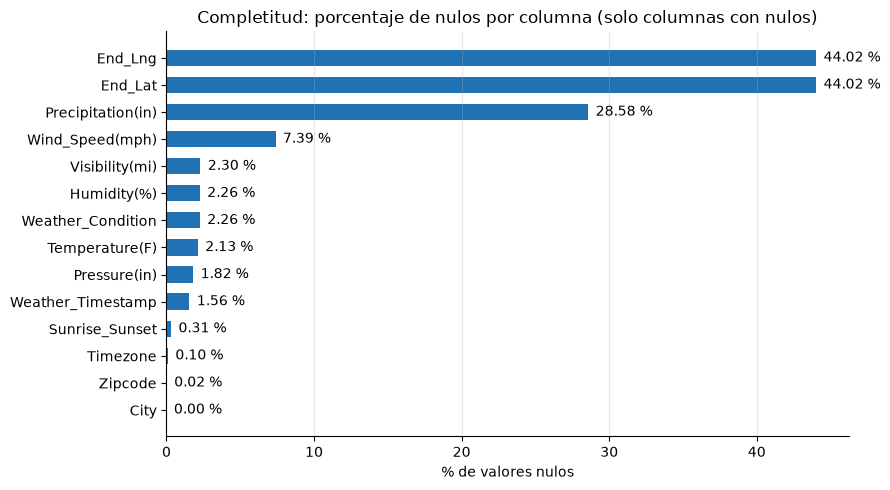

In [33]:
nulos = df[COLUMNAS].isna().mean().mul(100).sort_values()
nulos = nulos[nulos > 0]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(nulos.index, nulos.values, color="#2171b5", height=0.6)
for i, v in enumerate(nulos.values):
    ax.text(v + 0.5, i, f"{v:.2f} %", va="center")
ax.set_xlabel("% de valores nulos")
ax.set_title("Completitud: porcentaje de nulos por columna (solo columnas con nulos)")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "04_completitud_nulos")
plt.show()

**Interpretación:** los mayores faltantes están en `End_Lat`/`End_Lng` (**44,02 %**) y `Precipitation(in)` (**28,58 %**), seguidos de `Wind_Speed(mph)` (7,39 %). Las demás variables climáticas tienen alrededor de 2 %. Las columnas centrales de la pregunta (`Severity`, `Start_Time`, `Start_Lat`, `Start_Lng`, `State` y los elementos de la vía) **no aparecen en el gráfico porque están 100 % completas**.

### 8.2 Unicidad

In [34]:
evaluar("ID único", "Unicidad", ~df["ID"].duplicated(keep=False),
        "Un mismo accidente contado dos veces inflaría los conteos",
        "Mantenedor del dataset")
evaluar("Mismo inicio y misma ubicación no repetidos", "Unicidad",
        ~df.duplicated(subset=["Start_Time", "Start_Lat", "Start_Lng"]),
        "Posibles accidentes duplicados (reportados dos veces) que inflarían los conteos por hora y zona",
        "Equipo de análisis (marcar y revisar) / mantenedor del dataset")

### 8.3 Validez

In [35]:
# Umbrales justificados en la sección 8.8
TEMP_MIN, TEMP_MAX = -40, 130     # °F
PRES_MIN, PRES_MAX = 17, 32       # inHg, presión de estación (no corregida al nivel del mar)
VIENTO_MAX = 150                  # mph

evaluar("Severity entre 1 y 4", "Validez", df["Severity"].between(1, 4),
        "Un valor fuera de la escala no puede clasificarse como alto o bajo impacto",
        "Mantenedor del dataset")
evaluar("Start_Time dentro del período (2016 – mar 2023)", "Validez",
        df["Start_Time"].between(pd.Timestamp("2016-01-01"), pd.Timestamp("2023-04-01")),
        "Una fecha fuera del período indicaría un error de registro",
        "Mantenedor del dataset", base=con_dato("Start_Time"))
evaluar("Coordenadas de inicio dentro de EE.UU. continental", "Validez",
        df["Start_Lat"].between(24, 50) & df["Start_Lng"].between(-125, -66),
        "Un accidente ubicado fuera del país distorsionaría el análisis por zona",
        "Mantenedor del dataset")
evaluar(f"Temperature(F) entre {TEMP_MIN} y {TEMP_MAX}", "Validez",
        df["Temperature(F)"].between(TEMP_MIN, TEMP_MAX),
        "Temperaturas imposibles: error del sensor",
        "Proveedor de datos meteorológicos", base=con_dato("Temperature(F)"))
evaluar(f"Pressure(in) entre {PRES_MIN} y {PRES_MAX}", "Validez",
        df["Pressure(in)"].between(PRES_MIN, PRES_MAX),
        "Presiones físicamente imposibles: falla del sensor",
        "Proveedor de datos meteorológicos", base=con_dato("Pressure(in)"))
evaluar(f"Wind_Speed(mph) entre 0 y {VIENTO_MAX}", "Validez",
        df["Wind_Speed(mph)"].between(0, VIENTO_MAX),
        "Velocidades superiores a un huracán extremo: error de registro",
        "Proveedor de datos meteorológicos", base=con_dato("Wind_Speed(mph)"))
evaluar("Humidity(%) entre 0 y 100", "Validez", df["Humidity(%)"].between(0, 100),
        "Una humedad fuera de 0–100 % es imposible",
        "Proveedor de datos meteorológicos", base=con_dato("Humidity(%)"))
evaluar("Distance(mi) mayor o igual a 0", "Validez", df["Distance(mi)"] >= 0,
        "Una distancia negativa es imposible",
        "Mantenedor del dataset")

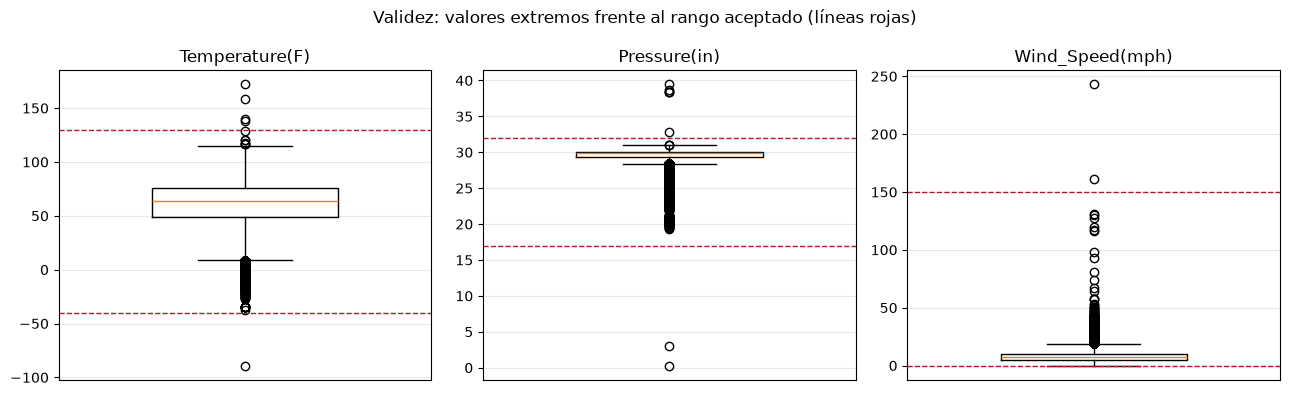

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (col, lim) in zip(axes, [("Temperature(F)", (TEMP_MIN, TEMP_MAX)),
                                  ("Pressure(in)", (PRES_MIN, PRES_MAX)),
                                  ("Wind_Speed(mph)", (0, VIENTO_MAX))]):
    ax.boxplot(df[col].dropna(), widths=0.5)
    for y in lim:
        ax.axhline(y, color="#b2182b", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Validez: valores extremos frente al rango aceptado (líneas rojas)")
plt.tight_layout()
guardar_figura(fig, "05_validez_extremos")
plt.show()

**Interpretación:** los puntos fuera de las líneas rojas son los registros que incumplen las reglas de validez. Son **casos aislados**: 5 en temperatura, 2 en viento y 8 en presión (valores como 0,30 o 39,45 inHg, típicos de una coma decimal mal ubicada o de un sensor averiado). Ninguno afecta a las variables centrales de la pregunta.



### 8.4 Consistencia (aquí está el hallazgo principal)

In [37]:
DURACION_MAX_H = 24
evaluar("End_Time posterior a Start_Time", "Consistencia", df["End_Time"] > df["Start_Time"],
        "Un accidente que termina antes de empezar tendría duración negativa",
        "Mantenedor del dataset", base=con_dato("End_Time") & con_dato("Start_Time"))
evaluar(f"Duración del accidente de máximo {DURACION_MAX_H} h", "Consistencia",
        df["Duracion_min"] <= DURACION_MAX_H * 60,
        "Duraciones irreales distorsionarían la medición del tiempo de bloqueo",
        "Equipo de análisis (marcar) / mantenedor del dataset", base=df["Duracion_min"] > 0)
evaluar("Clima medido a máximo 1 h del accidente", "Consistencia",
        (df["Weather_Timestamp"] - df["Start_Time"]).abs().dt.total_seconds() <= 3600,
        "El clima registrado podría no corresponder al momento del accidente",
        "Proveedor de datos meteorológicos",
        base=con_dato("Weather_Timestamp") & con_dato("Start_Time"))
evaluar("Si Distance > 0, debe existir End_Lat", "Consistencia", df["End_Lat"].notna(),
        "Hay accidentes con tramo afectado pero sin coordenadas de fin del tramo",
        "Mantenedor del dataset / fuentes", base=df["Distance(mi)"] > 0)

**¿Los faltantes de `End_Lat` dependen de la fuente?**

In [38]:
pd.crosstab(df["Source"], df["End_Lat"].isna().map({True: "End_Lat nulo", False: "End_Lat con dato"}),
            margins=True, margins_name="Total")

End_Lat,End_Lat con dato,End_Lat nulo,Total
Source,,,
Source1,302822,0,302822
Source2,0,231427,231427
Source3,0,6739,6739
Total,302822,238166,540988


**¿La severidad se mide igual en todas las fuentes?**

In [39]:
sev_fuente = pd.crosstab(df["Source"], df["Severity"], normalize="index").mul(100).round(2)
sev_fuente["% alto impacto (3–4)"] = sev_fuente[3] + sev_fuente[4]
sev_fuente

Severity,1,2,3,4,% alto impacto (3–4)
Source,,,,,
Source1,0.66,91.21,3.72,4.41,8.13
Source2,1.05,65.05,33.47,0.43,33.90
Source3,4.21,64.24,31.44,0.10,31.54


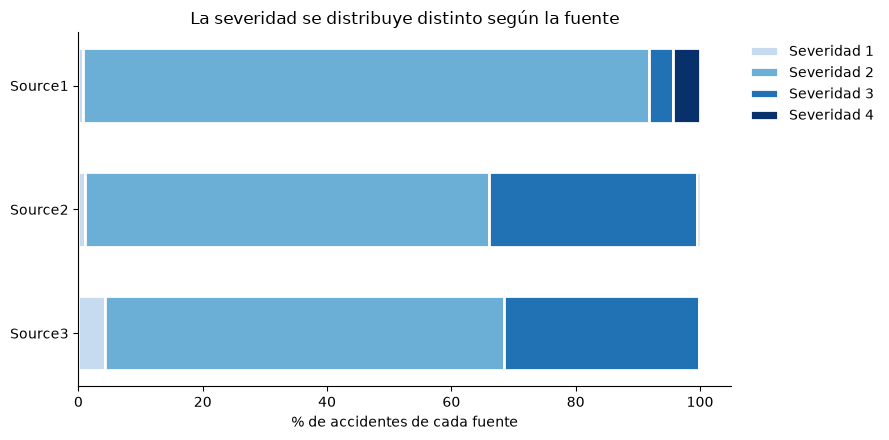

In [40]:
tabla_sev = pd.crosstab(df["Source"], df["Severity"], normalize="index").mul(100)

fig, ax = plt.subplots(figsize=(9, 4.5))
izquierda = np.zeros(len(tabla_sev))
for nivel, color in zip(tabla_sev.columns, ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]):
    ax.barh(tabla_sev.index, tabla_sev[nivel], left=izquierda, color=color,
            edgecolor="white", linewidth=2, label=f"Severidad {nivel}", height=0.6)
    izquierda += tabla_sev[nivel].values
ax.set_xlabel("% de accidentes de cada fuente")
ax.set_title("La severidad se distribuye distinto según la fuente")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "06_severidad_por_fuente")
plt.show()

**Interpretación de la consistencia entre fuentes**

1. **Las coordenadas de fin dependen 100 % de la fuente.** `Source1` siempre registra `End_Lat`/`End_Lng` (302 822 de 302 822), mientras que `Source2` (231 427) y `Source3` (6 739) **nunca** lo hacen. El 44,02 % de nulos **no es un faltante aleatorio**, sino una diferencia en cómo cada fuente registra los datos.

2. **La severidad no es comparable entre fuentes.** El porcentaje de accidentes de alto impacto (3–4) es:

| Fuente | Sev. 3 | Sev. 4 | % alto impacto |
|---|---|---|---|
| Source1 | 3,72 % | 4,41 % | **8,13 %** |
| Source2 | 33,47 % | 0,43 % | **33,90 %** |
| Source3 | 31,44 % | 0,10 % | **31,54 %** |

`Source2` clasifica como alto impacto **4 veces más** que `Source1`. Además, `Source1` concentra la severidad 4 y `Source2` la severidad 3. Esto indica que **cada fuente aplica un criterio distinto para asignar la severidad**.

**Consecuencia para la pregunta:** la pregunta define "colapso del tráfico" como severidad 3–4. Si una ciudad tiene más registros de `Source2`, parecerá tener más colapsos solo por cómo se registraron. **Toda comparación de severidad entre zonas u horarios debe controlar la fuente.**

### 8.5 Plausibilidad

In [41]:
evaluar("Distance(mi) mayor que 0", "Plausibilidad", df["Distance(mi)"] > 0,
        "Un accidente que afecta el tráfico debería afectar algún tramo; una distancia 0 parece un valor por defecto",
        "Mantenedor del dataset / fuentes")

**Interpretación:** **231 137 accidentes (42,73 %)** tienen tramo afectado igual a 0. Aunque 0 es un valor *posible*, no es *plausible* para un accidente que altera el tráfico: probablemente indica que la fuente no midió el tramo. Por eso `Distance(mi)` **no se usará** como medida principal del impacto; la pregunta se apoya en `Severity` (controlando la fuente).

### 8.6 Oportunidad

In [42]:
print(f"Cobertura: {df['Start_Time'].min():%Y-%m-%d} → {df['Start_Time'].max():%Y-%m-%d}")
anual = df.groupby("Anio").agg(accidentes=("ID", "size"),
                               desde=("Start_Time", "min"), hasta=("Start_Time", "max"))
display(anual)

# Un año es comparable si tiene al menos el 50 % de la mediana anual   (justificado en 8.8)
evaluar("Año con al menos 50 % de la mediana anual", "Oportunidad",
        anual["accidentes"].ge(0.5 * anual["accidentes"].median()),
        "Un año incompleto (2016 empieza en febrero; 2023 solo tiene enero–marzo) no es comparable con los demás",
        "Equipo de análisis (advertirlo al comparar años)")

Cobertura: 2016-02-08 → 2023-03-31


,accidentes,desde,hasta
Anio,,,
2016,28763,2016-02-08 07:59:35,2016-12-31 23:03:03
2017,50286,2017-01-01 00:26:08,2017-12-31 23:03:21
2018,62572,2018-01-01 01:05:42,2018-12-31 23:09:43
2019,66737,2019-01-01 00:03:14,2019-12-31 23:28:00
2020,82480,2020-01-01 00:43:50,2020-12-31 23:58:00
2021,109478,2021-01-01 00:05:00,2021-12-31 23:48:00
2022,123374,2022-01-01 00:37:00,2022-12-31 23:58:30
2023,17298,2023-01-01 00:00:00,2023-03-31 22:59:30


**Interpretación:** 2016 (28 763) y 2023 (17 298) quedan por debajo de la mitad de la mediana anual (~32 300) porque son **años incompletos**. Para la pregunta esto importa poco, porque se buscan patrones por **hora, día, clima y vía** y no tendencias entre años; pero cualquier comparación anual debe excluirlos o advertirlo.

### 8.7 Resultado consolidado

In [43]:
calidad = pd.DataFrame(resultados)
with pd.option_context("display.max_colwidth", 80):
    display(calidad)

,Dimensión,Regla,Evaluados,Incumplen,% Cumple,Impacto sobre el trabajo,Responsable
0,Completitud,Severity no nulo,540988,0,100.00,Sin severidad no se sabe si el accidente fue de alto impacto: es la variable...,Mantenedor del dataset
1,Completitud,Start_Time no nulo,540988,0,100.00,Sin fecha y hora no se puede responder la sub-pregunta 1 (cuándo),Mantenedor del dataset
2,Completitud,City no nulo,540988,19,100.00,Un accidente sin ciudad no puede compararse por zona urbana,Mantenedor del dataset
3,Completitud,Weather_Condition no nulo,540988,12232,97.74,Estos accidentes no podrán analizarse por condición climática (sub-pregunta 3),Proveedor de datos meteorológicos
4,Completitud,Visibility(mi) no nulo,540988,12456,97.70,Reduce la muestra para analizar la visibilidad como condición de riesgo,Proveedor de datos meteorológicos
5,Completitud,Wind_Speed(mph) no nulo,540988,39968,92.61,Reduce la muestra para analizar el viento,Proveedor de datos meteorológicos
6,Completitud,Precipitation(in) no nulo,540988,154617,71.42,Casi 3 de cada 10 accidentes no tienen dato de lluvia: no se puede medir su ...,Proveedor de datos meteorológicos / equipo (usar Weather_Condition)
7,Completitud,Sunrise_Sunset no nulo,540988,1689,99.69,Impide clasificar el accidente como diurno o nocturno,Mantenedor del dataset
8,Completitud,Timezone no nulo,540988,542,99.90,Sin zona horaria no se puede confirmar a qué hora local ocurrió,Mantenedor del dataset
9,Unicidad,ID único,540988,0,100.00,Un mismo accidente contado dos veces inflaría los conteos,Mantenedor del dataset


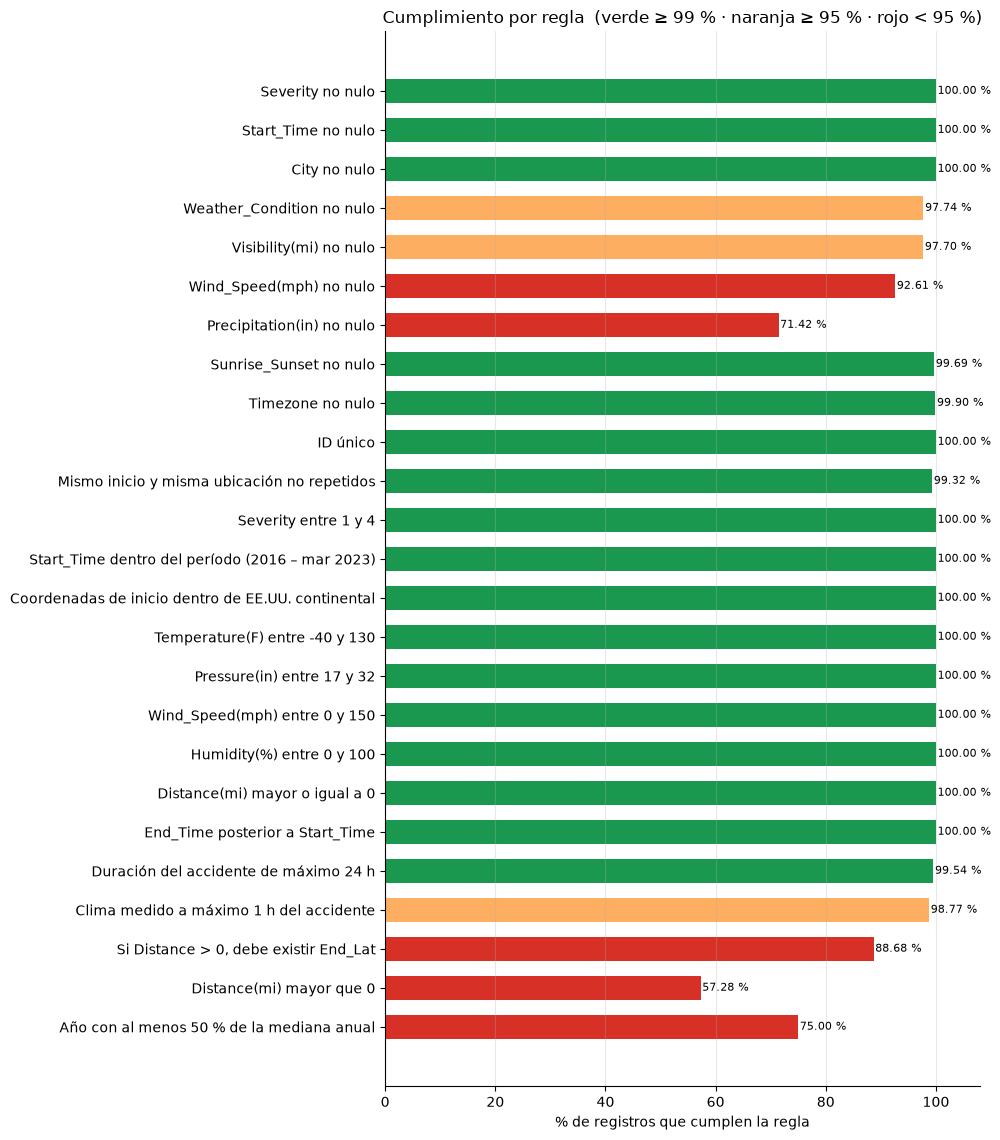

In [44]:
colores = calidad["% Cumple"].apply(lambda x: "#1a9850" if x >= 99 else ("#fdae61" if x >= 95 else "#d73027"))

fig, ax = plt.subplots(figsize=(10, 0.4 * len(calidad) + 1.5))
ax.barh(calidad["Regla"], calidad["% Cumple"], color=colores, height=0.6)
for i, v in enumerate(calidad["% Cumple"]):
    ax.text(v + 0.3, i, f"{v:.2f} %", va="center", fontsize=8)
ax.set_xlim(0, 108)
ax.set_xlabel("% de registros que cumplen la regla")
ax.set_title("Cumplimiento por regla  (verde ≥ 99 % · naranja ≥ 95 % · rojo < 95 %)")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "07_cumplimiento_reglas")
plt.show()

In [45]:
regla_a_ver = "Duración del accidente de máximo 24 h"
df.loc[fallas[regla_a_ver],
       ["ID", "Source", "Severity", "Start_Time", "End_Time", "Duracion_min", "City", "State"]].head(5)

,ID,Source,Severity,Start_Time,End_Time,Duracion_min,City,State
9182,A-154385,Source2,3,2016-10-06 15:00:41,2016-10-07 15:30:00,1469.316667,Metter,GA
42814,A-646586,Source2,3,2022-04-05 04:39:20,2022-04-18 07:27:24,18888.066667,Texas City,TX
48653,A-756285,Source2,3,2021-12-31 02:22:33,2022-01-03 04:12:00,4429.450000,Broomfield,CO
53187,A-756297,Source2,3,2021-12-31 02:22:33,2022-01-03 08:55:00,4712.450000,Boulder,CO
70343,A-1146585,Source2,3,2021-02-15 05:06:50,2021-02-19 04:40:43,5733.883333,Houston,TX


In [46]:
regla_a_ver = f"Pressure(in) entre {PRES_MIN} y {PRES_MAX}"
df.loc[fallas[regla_a_ver],
       ["ID", "Source", "Start_Time", "City", "State", "Pressure(in)", "Temperature(F)"]].head(5)

,ID,Source,Start_Time,City,State,Pressure(in),Temperature(F)
48062,A-515281,Source2,2022-09-06 08:22:28,Pomona,CA,38.44,97.0
217439,A-3288068,Source2,2017-09-05 16:37:10,Diamond Bar,CA,0.30,NaN
252346,A-3750215,Source1,2022-09-08 13:52:52,Plant City,FL,39.45,84.0
264259,A-3530675,Source1,2017-01-12 06:47:51,San Bernardino,CA,2.99,53.6
278087,A-3996972,Source1,2022-12-25 11:39:23,Mentor,OH,38.69,12.0


### 8.8 Interpretación de la evaluación de calidad

Se evaluaron **25 reglas en las 6 dimensiones**. Las reglas sobre las **variables centrales de la pregunta** (severidad, fecha y hora, coordenadas de inicio, estado y elementos de la vía) **se cumplen al 100 %** en completitud y validez, y no hay identificadores duplicados.

**Las reglas con más incumplimiento:**

| Regla | Cumplimiento | Qué significa |
|---|---|---|
| Distance(mi) mayor que 0 | 57,28 % (231 137 fallan) | El tramo afectado parece no medirse en muchos registros |
| Precipitation(in) no nulo | 71,42 % (154 617 fallan) | La intensidad de la lluvia no es confiable |
| Año con ≥ 50 % de la mediana | 75,00 % (2 de 8 años) | 2016 y 2023 están incompletos |
| Si Distance > 0, debe existir End_Lat | 88,68 % (35 067 fallan) | Fuentes que no registran el fin del tramo |
| Wind_Speed(mph) no nulo | 92,61 % (39 968 fallan) | Faltante moderado en viento |
| Clima medido a ≤ 1 h del accidente | 98,77 % (6 566 fallan) | Clima posiblemente desfasado |
| Mismo inicio y ubicación no repetidos | 99,32 % (3 698 fallan) | Posibles duplicados |
| Duración ≤ 24 h | 99,54 % (2 474 fallan) | Duraciones irreales |

**Justificación de los umbrales**

- **Temperatura entre −40 y 130 °F (−40 a 54 °C):** cubre las temperaturas que se registran normalmente en EE.UU. continental. Los valores de la muestra fuera de ese rango (−89 °F y 172 °F) no son físicamente creíbles en una carretera.
- **Presión entre 17 y 32 inHg:** `Pressure(in)` es presión de **estación**, que baja con la altitud. Las carreteras pavimentadas más altas de EE.UU. (~4 300 m) rondan 17,5 inHg, y el récord de presión alta al nivel del mar es ~31,9 inHg. Valores como 0,30 o 38,44 son imposibles. (Un umbral de 25 inHg habría marcado como error a 6 725 accidentes legítimos de zonas de montaña; ver 8.3).
- **Viento máximo de 150 mph (241 km/h):** equivale a un huracán de categoría 4. Un valor de 243 mph en un registro de tránsito es un error.
- **Duración máxima de 24 horas:** un accidente puede bloquear una vía varias horas, pero un impacto de más de un día no corresponde a un accidente común (sería una obra o cierre prolongado).
- **Clima medido a máximo 1 hora del accidente:** las estaciones meteorológicas reportan aproximadamente cada hora; más allá de eso, el clima registrado puede no ser el que había en el momento del accidente.
- **Año con al menos 50 % de la mediana anual:** un año con menos de la mitad del volumen típico no representa el año completo.

**Lección de dominio: la fuente es una variable más.** Una evaluación que solo midiera nulos habría concluido que la severidad es perfecta (100 % completa y válida). Al cruzarla con la fuente se descubre que **no es consistente**: es el problema más importante del dataset para nuestra pregunta, aunque no aparezca como un "error" en ninguna regla individual.

---
## 9. Diagnóstico final

| # | Problema | Dimensión | Registros / % afectado | Cómo altera la decisión | Acción propuesta | Quién debe atenderla |
|---|---|---|---|---|---|---|
| 1 | **La severidad no se mide igual en todas las fuentes** (problema crítico) | Consistencia | **Toda la muestra:** 302 822 (55,98 %) de Source1 frente a 238 166 (44,02 %) de Source2 y Source3. Alto impacto: 8,13 % vs 33,90 % vs 31,54 % | La pregunta define "colapso" como severidad 3–4. Una zona con más registros de Source2 parecerá tener más colapsos solo por cómo se registraron, y las autoridades podrían **asignar recursos a zonas equivocadas** | Analizar la severidad **por separado para cada fuente** (o solo con Source1, la más grande y completa) y usar `Source` como variable de control en toda comparación | Equipo de análisis (corto plazo); el mantenedor del dataset debe documentar el criterio de severidad de cada fuente |
| 2 | **Precipitación incompleta** | Completitud | **154 617 registros (28,58 %)** sin dato | Con casi un tercio de faltantes, el efecto de la lluvia en los colapsos podría subestimarse o sobreestimarse (sub-pregunta 3) | Usar `Weather_Condition` (97,74 % completa) agrupada en categorías (lluvia, nieve, niebla, despejado) como variable climática principal; `Precipitation` solo como apoyo | Equipo de análisis; a largo plazo, el proveedor de datos meteorológicos |
| 3 | **Valores inválidos y posibles duplicados** | Validez · Consistencia · Unicidad | Presión imposible: 8 (< 0,01 %) · duración > 24 h: 2 474 (0,46 %) · clima desfasado: 6 566 (1,23 %) · mismo inicio y ubicación: 3 698 (0,68 %) | Los duplicados inflan el conteo de accidentes en ciertas horas y zonas; las duraciones irreales distorsionan el tiempo de bloqueo | **Marcar** estos registros con variables indicadoras (no borrar) y excluirlos en la etapa de limpieza, documentando cuántos se retiran | Equipo de análisis, en la siguiente etapa del proyecto |

### Conclusión

Las variables de **fecha-hora y ubicación inicial** tienen 100 % de completitud y validez, y las variables de **tipo de vía** (`Traffic_Signal`, `Crossing`, `Junction`, etc.) son booleanas sin valores nulos. La **severidad** también está completa y es válida (valores 1–4), pero **no es consistente entre fuentes**, que es el hallazgo más importante del diagnóstico.

Por lo tanto, **los datos sí permiten responder la pregunta, siempre que el análisis controle la fuente**: comparar patrones dentro de una misma fuente es confiable, mientras que mezclarlas sin control distorsionaría la identificación de las horas y zonas de alto impacto. Para el clima, la variable confiable es `Weather_Condition`, no `Precipitation(in)`.

**Limitaciones de esta entrega**
- Se trabajó con una muestra aleatoria del 7 % (semilla fija); los porcentajes deberían ser muy similares en el dataset completo, pero los conteos absolutos no.
- Los datos provienen de reportes de tráfico: no incluyen todos los accidentes ocurridos, sino los que las fuentes captaron.

### Respuestas al cierre esperado

| Pregunta de la rúbrica | Respuesta del equipo |
|---|---|
| **1. ¿Qué problema de calidad encontraron?** | El principal es de **consistencia**: la severidad (variable que define el "colapso del tráfico") se asigna con criterios distintos según la fuente. Le siguen la **completitud** de la precipitación y un grupo pequeño de valores **inválidos** y posibles **duplicados**. |
| **2. ¿Cuántos registros o qué porcentaje afecta?** | Severidad: afecta a la comparación de **toda la muestra** (Source1 = 55,98 % con 8,13 % de alto impacto, frente a 33,90 % en Source2). Precipitación: **154 617 registros (28,58 %)** sin dato. Inválidos y posibles duplicados: menos de 1,3 % por regla (clima desfasado 1,23 %, mismo inicio y ubicación 0,68 %, duración > 24 h 0,46 %, presión imposible 8 registros). |
| **3. ¿Cómo puede alterar la descripción o la decisión?** | Una zona o franja horaria con más registros de Source2 aparecería con más "colapsos" solo por la forma de registrar, y los recursos de patrullaje y emergencias se asignarían a lugares equivocados. Sin dato de lluvia, el efecto del clima quedaría sesgado. |
| **4. ¿Qué acción proponen y quién debe atenderla?** | El **equipo de análisis** comparará la severidad dentro de cada fuente (o solo con Source1), usará `Weather_Condition` agrupada como variable climática y marcará —sin borrar— los registros inválidos para la etapa de limpieza. El **mantenedor del dataset** debería documentar el criterio de severidad de cada fuente. |

---
## 10. Trazabilidad: artefactos exportados

Para que el informe y las siguientes entregas usen exactamente las mismas tablas, se exportan a la capa **Gold** (`data/gold/us_accidents/`). Los gráficos ya se guardaron en `outputs/us_accidents/` al generarse.

In [47]:
# Celda 10.1: exportar tablas del EDA a Gold
artefactos = {
    "diccionario_datos.csv": diccionario,
    "catalogo_tecnico.csv": catalogo.rename_axis("Columna").reset_index(),
    "perfil_descriptivo_numerico.csv": perfil_num.round(4).rename_axis("Columna").reset_index(),
    "perfil_descriptivo_categorico.csv": perfil_cat.rename_axis("Columna").reset_index(),
    "reporte_calidad_dama.csv": calidad,
}
for nombre, tabla in artefactos.items():
    tabla.to_csv(GOLD_DIR / nombre, index=False, encoding="utf-8-sig")

print("Gold:")
for p in sorted(GOLD_DIR.glob("*.csv")):
    print(f"  {p.relative_to(PROJECT_ROOT)}")
print("Gráficos:")
for p in sorted(OUTPUT_DIR.glob("*.png")):
    print(f"  {p.relative_to(PROJECT_ROOT)}")

Gold:
  data\gold\us_accidents\catalogo_tecnico.csv
  data\gold\us_accidents\diccionario_datos.csv
  data\gold\us_accidents\perfil_descriptivo_categorico.csv
  data\gold\us_accidents\perfil_descriptivo_numerico.csv
  data\gold\us_accidents\reporte_calidad_dama.csv
Gráficos:
  outputs\us_accidents\01_distribucion_severidad.png
  outputs\us_accidents\02_top10_estados.png
  outputs\us_accidents\03_accidentes_por_anio.png
  outputs\us_accidents\04_completitud_nulos.png
  outputs\us_accidents\05_validez_extremos.png
  outputs\us_accidents\06_severidad_por_fuente.png
  outputs\us_accidents\07_cumplimiento_reglas.png
